## Experiment No: 03
#### PCA on the Wine dataset: dimensionality reduction, visualization and variance retained

#### Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

#### Load the Dataset

In [2]:
try:
    dataset = pd.read_csv('Wine.csv')
    X = dataset.iloc[:, :-1].values
    y = dataset.iloc[:, -1].values
    feature_names = list(dataset.columns[:-1])
    print("Loaded Wine.csv")
except FileNotFoundError:
    from sklearn.datasets import load_wine
    wine = load_wine()
    X, y = wine.data, wine.target + 1          
    feature_names = list(wine.feature_names)
    print("Wine.csv not found - using sklearn load_wine()")

print("Shape of X:", X.shape)
print("Classes   :", np.unique(y), "| samples per class:", np.bincount(y)[1:])
pd.DataFrame(X, columns=feature_names).head()

Loaded Wine.csv
Shape of X: (178, 13)
Classes   : [1 2 3] | samples per class: [59 71 48]


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


#### Train-Test Split

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (142, 13)  Test: (36, 13)


#### Feature Scaling (fitted on the training set only)

In [4]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

#### Variance Explained by All Principal Components

In [5]:
pca_full = PCA()
pca_full.fit(X_train)
var_ratio = pca_full.explained_variance_ratio_
cum_var = np.cumsum(var_ratio)

print("Explained variance ratio:")
for i, (v, c) in enumerate(zip(var_ratio, cum_var), start=1):
    print(f"  PC{i:<2}: {v*100:6.2f}%   (cumulative: {c*100:6.2f}%)")

for t in (0.90, 0.95):
    print(f"\nComponents needed to retain {int(t*100)}% variance: {np.argmax(cum_var >= t) + 1}")

Explained variance ratio:
  PC1 :  36.88%   (cumulative:  36.88%)
  PC2 :  19.32%   (cumulative:  56.20%)
  PC3 :  10.75%   (cumulative:  66.96%)
  PC4 :   7.42%   (cumulative:  74.38%)
  PC5 :   6.25%   (cumulative:  80.62%)
  PC6 :   4.91%   (cumulative:  85.53%)
  PC7 :   4.12%   (cumulative:  89.65%)
  PC8 :   2.50%   (cumulative:  92.15%)
  PC9 :   2.31%   (cumulative:  94.45%)
  PC10:   1.86%   (cumulative:  96.32%)
  PC11:   1.73%   (cumulative:  98.05%)
  PC12:   1.25%   (cumulative:  99.30%)
  PC13:   0.70%   (cumulative: 100.00%)

Components needed to retain 90% variance: 8

Components needed to retain 95% variance: 10


#### Variance Plots (individual + cumulative)

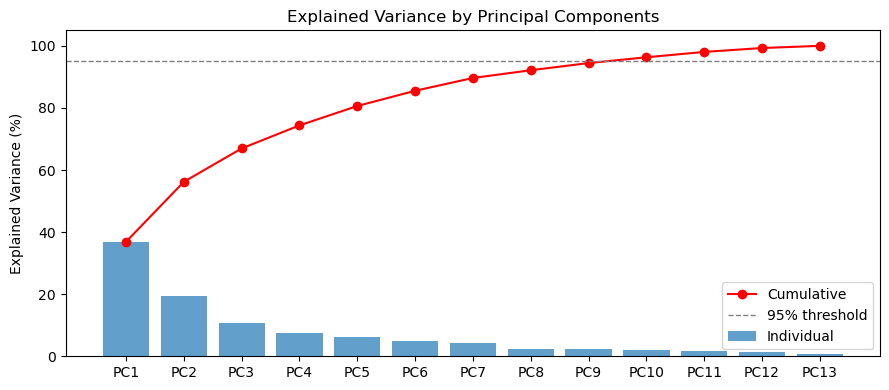

In [6]:
pcs = [f'PC{i}' for i in range(1, len(var_ratio) + 1)]
plt.figure(figsize=(9, 4))
plt.bar(pcs, var_ratio * 100, alpha=0.7, label='Individual')
plt.plot(pcs, cum_var * 100, 'ro-', label='Cumulative')
plt.axhline(95, color='gray', linestyle='--', linewidth=1, label='95% threshold')
plt.ylabel('Explained Variance (%)')
plt.title('Explained Variance by Principal Components')
plt.legend()
plt.tight_layout()
plt.show()

#### Apply PCA (13 features to 2 components)

In [7]:
pca = PCA(n_components=2)
X_train = pca.fit_transform(X_train)
X_test = pca.transform(X_test)

retained = pca.explained_variance_ratio_.sum() * 100
print(f"Variance retained with 2 PCs : {retained:.2f}%")
print(f"Information lost             : {100 - retained:.2f}%")

Variance retained with 2 PCs : 56.20%
Information lost             : 43.80%


#### Logistic Regression on the Reduced Data

In [8]:
classifier = LogisticRegression(random_state=0)
classifier.fit(X_train, y_train)
y_pred = classifier.predict(X_test)

print("Test accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("\nClassification Report:\n", classification_report(y_test, y_pred, zero_division=0))

Test accuracy: 0.972

Classification Report:
               precision    recall  f1-score   support

           1       0.93      1.00      0.97        14
           2       1.00      0.94      0.97        16
           3       1.00      1.00      1.00         6

    accuracy                           0.97        36
   macro avg       0.98      0.98      0.98        36
weighted avg       0.97      0.97      0.97        36



#### Confusion Matrix

[[14  0  0]
 [ 1 15  0]
 [ 0  0  6]]


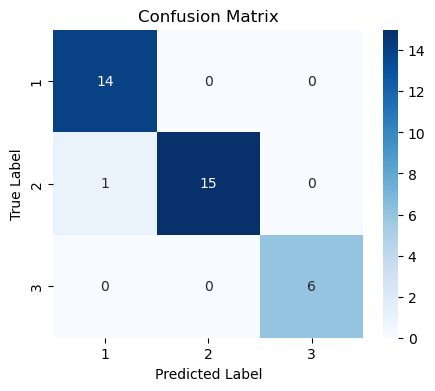

In [9]:
cm = confusion_matrix(y_test, y_pred)
print(cm)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

#### Visualising the Training Set Results

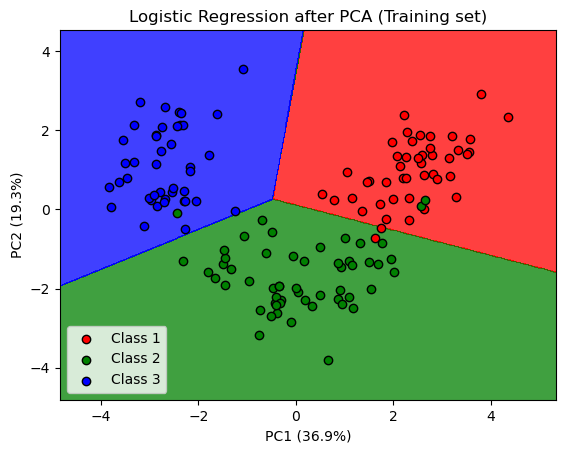

In [10]:
def plot_regions(X_set, y_set, title):
    X1, X2 = np.meshgrid(np.arange(X_set[:, 0].min() - 1, X_set[:, 0].max() + 1, 0.02),
                         np.arange(X_set[:, 1].min() - 1, X_set[:, 1].max() + 1, 0.02))
    cmap = ListedColormap(('red', 'green', 'blue'))
    plt.contourf(X1, X2, classifier.predict(np.c_[X1.ravel(), X2.ravel()]).reshape(X1.shape),
                 alpha=0.75, cmap=cmap)
    plt.xlim(X1.min(), X1.max()); plt.ylim(X2.min(), X2.max())
    for i, j in enumerate(np.unique(y_set)):
        plt.scatter(X_set[y_set == j, 0], X_set[y_set == j, 1],
                    c=[cmap(i)], edgecolor='k', label=f'Class {j}')
    plt.title(title)
    plt.xlabel(f'PC1 ({var_ratio[0]*100:.1f}%)')
    plt.ylabel(f'PC2 ({var_ratio[1]*100:.1f}%)')
    plt.legend()
    plt.show()

plot_regions(X_train, y_train, 'Logistic Regression after PCA (Training set)')

#### Visualising the Test Set Results

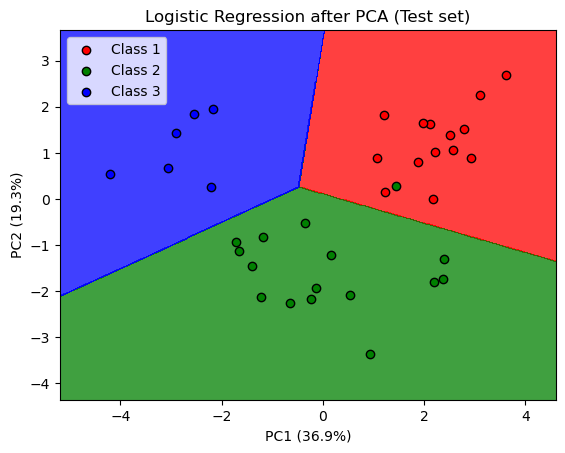

In [11]:
plot_regions(X_test, y_test, 'Logistic Regression after PCA (Test set)')

#### What do the Principal Components Represent?

In [12]:
loadings = pd.DataFrame(pca.components_.T, index=feature_names, columns=['PC1', 'PC2'])
print("Top contributing features:")
print("PC1:", list(loadings['PC1'].abs().sort_values(ascending=False).index[:3]))
print("PC2:", list(loadings['PC2'].abs().sort_values(ascending=False).index[:3]))
loadings.round(3)

Top contributing features:
PC1: ['Flavanoids', 'Total_Phenols', 'OD280']
PC2: ['Color_Intensity', 'Alcohol', 'Proline']


,PC1,PC2
Alcohol,0.130,0.498
Malic_Acid,-0.245,0.232
Ash,-0.010,0.315
Ash_Alcanity,-0.241,-0.023
Magnesium,0.126,0.258
Total_Phenols,0.389,0.101
Flavanoids,0.428,0.021
Nonflavanoid_Phenols,-0.305,0.040
Proanthocyanins,0.308,0.067
Color_Intensity,-0.110,0.531


**Conclusion:** PCA reduced the Wine dataset from 13 features to 2 principal components. These 2 components retain 56.20% of the total variance (PC1 = 36.88%, PC2 = 19.32%), so 43.80% of the information is lost. About 8 components are needed to retain 90% of the variance and 10 for 95%. Even with only 2 components, Logistic Regression reaches a test accuracy of about 0.97 and the three wine classes are clearly separated in the decision-region plots, because the class-related variation lies mainly along PC1 and PC2. This shows the trade-off in PCA: fewer dimensions give easier visualization and lower computation, at the cost of some information.